In [21]:
# Load the 200 m blocks and keep the clean fallow ones
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import r2_score

FILE = "../../Processed Data/Downscaling_Dataset.xlsx"
blocks = pd.read_excel(FILE, sheet_name="Blocks 200m")
blocks["Date"] = pd.to_datetime(blocks["Date"]).dt.strftime("%Y-%m-%d")

data = blocks[(blocks["Crop"] == "Fallow") & (blocks["Block_Type"] == "Clean")].copy()
print("Blocks:", sorted(data["Block_ID"].unique()))   # B0_0 to B0_3
print("Rows:", len(data))                             # 4 blocks x 6 dates = 24

Blocks: ['B0_0', 'B0_1', 'B0_2', 'B0_3']
Rows: 24


In [22]:
# Inputs and target
features = ["HH_dB" ,"HV_HH_Ratio"]
target = "SME2"

# Block minus the field average on the same date
data["HH_diff"] = data["HH_dB"] - data.groupby("Date")["HH_dB"].transform("mean")
data["SM_diff"] = data["SME2"] - data.groupby("Date")["SME2"].transform("mean")
data[["Date", "Block_ID", "HH_dB", "HH_diff", "SME2", "SM_diff"]].head(8).round(4)

,Date,Block_ID,HH_dB,HH_diff,SME2,SM_diff
0,2026-02-04,B0_0,-14.0984,0.9862,0.2231,-0.0032
1,2026-02-04,B0_1,-15.4568,-0.3722,0.2277,0.0015
2,2026-02-04,B0_2,-15.3956,-0.3110,0.2238,-0.0024
3,2026-02-04,B0_3,-15.3877,-0.3031,0.2303,0.0040
20,2026-02-10,B0_0,-14.9690,0.6807,0.1834,0.0023
21,2026-02-10,B0_1,-15.5727,0.0771,0.1832,0.0021
22,2026-02-10,B0_2,-15.7200,-0.0703,0.1726,-0.0085
23,2026-02-10,B0_3,-16.3373,-0.6875,0.1852,0.0041


In [23]:
# Leave-one-date-out test: train on 5 dates, test on the hidden date
# The model gives beta (moisture change per dB). NASA's equation then predicts each block:
#   block moisture - field moisture = beta * (block HH - field HH)
models = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=0),
                      {"max_depth": [2, 3, None], "min_samples_leaf": [1, 3, 5]}),
}

predictions = {}
for name, (model, settings) in models.items():
    pred = pd.Series(0.0, index=data.index)
    for date in data["Date"].unique():
        train = data[data["Date"] != date]
        test = data[data["Date"] == date]

        search = GridSearchCV(model, settings, cv=LeaveOneGroupOut(), scoring="neg_root_mean_squared_error")
        search.fit(train[features], train[target], groups=train["Date"])     # tuned on the 5 training dates only
        beta = np.polyfit(train["HH_dB"], search.predict(train[features]), 1)[0]

        pattern = beta * test["HH_diff"]
        pred[test.index] = pattern - pattern.mean()
        print(f"{name:13s} hidden {date}: beta = {beta:.4f}")
    predictions[name] = pred

Ridge         hidden 2026-02-04: beta = 0.0176
Ridge         hidden 2026-02-10: beta = 0.0148
Ridge         hidden 2026-02-17: beta = 0.0158
Ridge         hidden 2026-02-28: beta = 0.0145
Ridge         hidden 2026-03-01: beta = 0.0176
Ridge         hidden 2026-03-13: beta = 0.0141
Random Forest hidden 2026-02-04: beta = 0.0218
Random Forest hidden 2026-02-10: beta = 0.0213
Random Forest hidden 2026-02-17: beta = 0.0135
Random Forest hidden 2026-02-28: beta = 0.0161
Random Forest hidden 2026-03-01: beta = 0.0197
Random Forest hidden 2026-03-13: beta = 0.0213


In [24]:
# Evaluate against no downscaling (every block = field average)
actual = data["SM_diff"]
print(f"No downscaling: RMSE = {np.sqrt(np.mean(actual ** 2)):.4f}            (expected 0.0166)")
for name, pred in predictions.items():
    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    print(f"{name:13s} : RMSE = {rmse:.4f}, R2 = {r2_score(actual, pred):.3f}   (Ridge 0.0122 / 0.454, Forest 0.0123 / 0.448)")

No downscaling: RMSE = 0.0166            (expected 0.0166)
Ridge         : RMSE = 0.0104, R2 = 0.602   (Ridge 0.0122 / 0.454, Forest 0.0123 / 0.448)
Random Forest : RMSE = 0.0126, R2 = 0.423   (Ridge 0.0122 / 0.454, Forest 0.0123 / 0.448)


In [25]:
# Ridge error on each hidden date: only Mar 1 (the most varied date) beats no downscaling
error = actual - predictions["Ridge"]
per_date = pd.DataFrame({
    "No downscaling": np.sqrt((actual ** 2).groupby(data["Date"]).mean()),
    "NASA equation": np.sqrt((error ** 2).groupby(data["Date"]).mean()),
})
per_date["Better"] = per_date["NASA equation"] < per_date["No downscaling"]
per_date.round(4)

,No downscaling,NASA equation,Better
Date,,,
2026-02-04,0.0029,0.0121,False
2026-02-10,0.0050,0.0089,False
2026-02-17,0.0110,0.0137,False
2026-02-28,0.0154,0.0079,True
2026-03-01,0.0348,0.0058,True
2026-03-13,0.0065,0.0121,False


In [26]:
# Final beta: Ridge trained on all 6 dates
model, settings = models["Ridge"]
search = GridSearchCV(model, settings, cv=LeaveOneGroupOut(), scoring="neg_root_mean_squared_error")
search.fit(data[features], data[target], groups=data["Date"])
beta = np.polyfit(data["HH_dB"], search.predict(data[features]), 1)[0]
print(f"Final beta = {beta:.4f} m3/m3 per dB   (expected 0.0171)")

Final beta = 0.0158 m3/m3 per dB   (expected 0.0171)


In [27]:
# Downscale: piece moisture = block SME2 + beta * (piece HH - block HH)
# Then shift so the pieces average back (by pixel count) to NASA's block value
maps = {}
for size in ["100m", "50m"]:
    p = pd.read_excel(FILE, sheet_name=f"Pieces {size}")
    p["Date"] = pd.to_datetime(p["Date"]).dt.strftime("%Y-%m-%d")
    p = p[p["Block_ID"].isin(["B0_0", "B0_1", "B0_2", "B0_3"])].copy()

    p["Pattern"] = beta * (p["HH_dB"] - p["Block_HH_dB"])
    p["Weighted"] = p["Pattern"] * p["Pixels"]
    by_block = p.groupby(["Date", "Block_ID"])
    shift = by_block["Weighted"].transform("sum") / by_block["Pixels"].transform("sum")
    p["Downscaled_SM"] = p["Block_SME2"] + p["Pattern"] - shift

    maps[size] = p
    print(size, "pieces:", len(p))   # 96 and 384

100m pieces: 96
50m pieces: 384


In [28]:
# Check: each block's pieces average back to NASA's value
for size, p in maps.items():
    p["Weighted_SM"] = p["Downscaled_SM"] * p["Pixels"]
    by_block = p.groupby(["Date", "Block_ID"])
    average = by_block["Weighted_SM"].sum() / by_block["Pixels"].sum()
    gap = (average - by_block["Block_SME2"].first()).abs().max()
    print(f"{size}: largest gap from NASA = {gap:.1e}")   # about 0

100m: largest gap from NASA = 5.6e-17
50m: largest gap from NASA = 5.6e-17


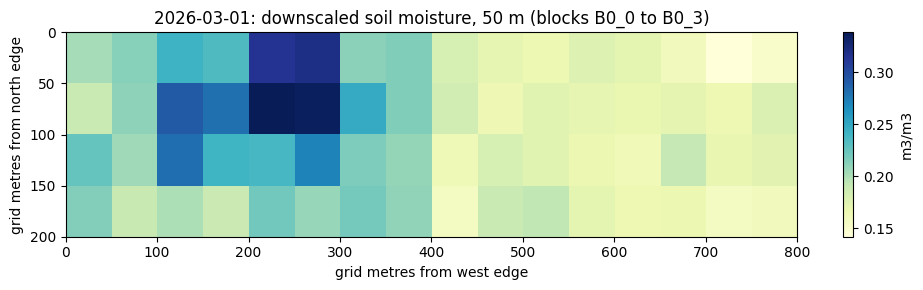

In [29]:
# Map of Mar 1 at 50 m: 4 blocks side by side, each 4 x 4 pieces
day = maps["50m"][maps["50m"]["Date"] == "2026-03-01"].copy()
day["row"] = day["Piece_ID"].str[1].astype(int)
day["col"] = day["Block_ID"].str[-1].astype(int) * 4 + day["Piece_ID"].str[3].astype(int)
grid = day.pivot(index="row", columns="col", values="Downscaled_SM")

plt.figure(figsize=(10, 3))
plt.imshow(grid, cmap="YlGnBu", aspect="auto", extent=[0, 800, 200, 0])
plt.colorbar(label="m3/m3")
plt.title("2026-03-01: downscaled soil moisture, 50 m (blocks B0_0 to B0_3)")
plt.xlabel("grid metres from west edge"); plt.ylabel("grid metres from north edge")
plt.tight_layout(); plt.show()

In [30]:
# Save (separate file, so the main notebook's results stay as they are)
with pd.ExcelWriter("../../Processed Data/Final_Soil_Moisture_Results_Simple.xlsx") as writer:
    per_date.to_excel(writer, sheet_name="Results per Date")
    maps["100m"].to_excel(writer, sheet_name="Map 100m", index=False)
    maps["50m"].to_excel(writer, sheet_name="Map 50m", index=False)
print("Saved Final_Soil_Moisture_Results_Simple.xlsx")

Saved Final_Soil_Moisture_Results_Simple.xlsx
